# 🛡️ SafeGuard AI — Dataset Exploration & Visualization Notebook
Notebook này hỗ trợ theo dõi, trực quan hóa và phân tích quá trình xử lý bộ dữ liệu lừa đảo Việt Nam (**PhishVN**) và **Dữ liệu lừa đảo Quốc tế**.

In [1]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Setting visualization styles
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
print("✅ Imported visualization & analysis libraries.")

✅ Imported visualization & analysis libraries.


## 📌 1. Nạp và Thống kê Tổng quan PhishVN Dataset (ver1 & ver2)

In [2]:
data_dir = "data"
path_ver1 = os.path.join(data_dir, "data-phising-VN-ver1", "dataset_url.csv")
path_ver2 = os.path.join(data_dir, "data-phising-VN-ver2", "dataset_url.csv")

df_ver1 = pd.read_csv(path_ver1, low_memory=False) if os.path.exists(path_ver1) else pd.DataFrame()
df_ver2 = pd.read_csv(path_ver2, low_memory=False) if os.path.exists(path_ver2) else pd.DataFrame()

print(f"📊 PhishVN ver1 shape: {df_ver1.shape}")
print(f"📊 PhishVN ver2 shape: {df_ver2.shape}")

# Combine unique records
combined_df = pd.concat([df_ver1, df_ver2], ignore_index=True).drop_duplicates(subset=["id"])
print(f"🔥 Total Unique Combined Records: {len(combined_df)}")

📊 PhishVN ver1 shape: (8510, 23)
📊 PhishVN ver2 shape: (51362, 29)
🔥 Total Unique Combined Records: 51373


## 🎯 2. Trực quan hóa Tỷ lệ URL Lừa đảo vs Hợp pháp (Phishing vs Legitimate)

label
phishing    36871
benign      14502
Name: count, dtype: int64


C:\Users\Admin\AppData\Local\Temp\ipykernel_12036\4144580824.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label_counts.index, y=label_counts.values, ax=ax[0], palette="magma")


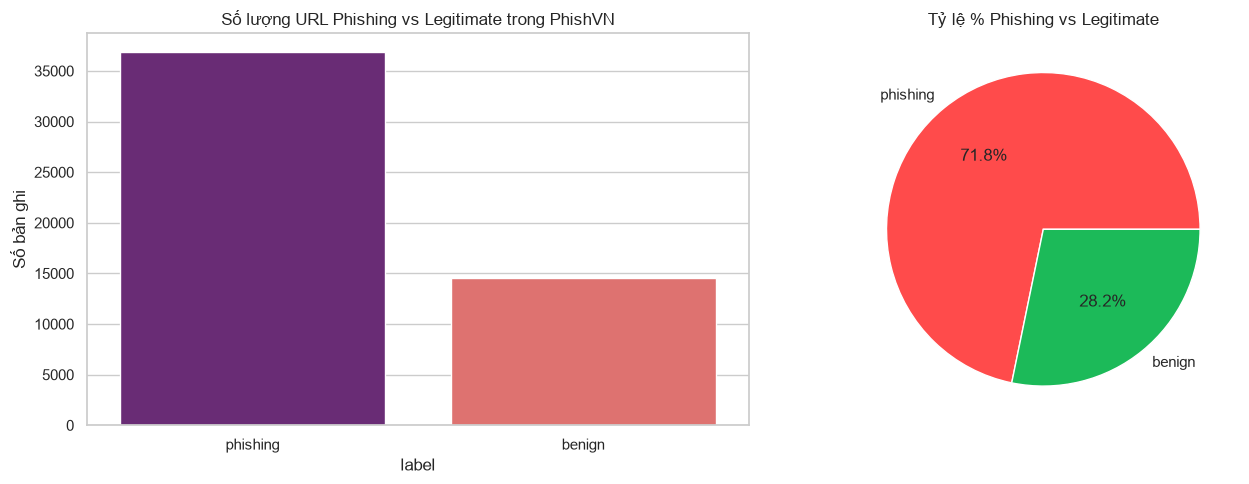

In [3]:
if not combined_df.empty and "label" in combined_df.columns:
    label_counts = combined_df["label"].value_counts()
    print(label_counts)
    
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    
    # Bar Chart
    sns.barplot(x=label_counts.index, y=label_counts.values, ax=ax[0], palette="magma")
    ax[0].set_title("Số lượng URL Phishing vs Legitimate trong PhishVN")
    ax[0].set_ylabel("Số bản ghi")
    
    # Pie Chart
    ax[1].pie(label_counts.values, labels=label_counts.index, autopct='%1.1f%%', colors=["#ff4b4b", "#1cba59"])
    ax[1].set_title("Tỷ lệ % Phishing vs Legitimate")
    
    plt.tight_layout()
    plt.show()

## 🏢 3. Thống kê theo Kịch bản Giả mạo (Impersonation Scenarios)

C:\Users\Admin\AppData\Local\Temp\ipykernel_12036\482003001.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=scenario_counts.values, y=scenario_counts.index, palette="viridis")


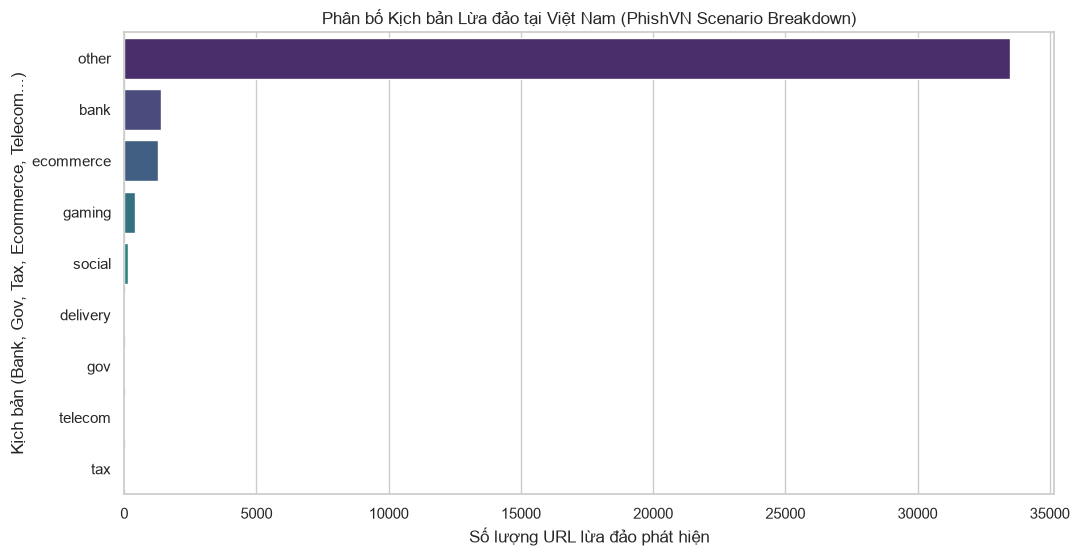

In [4]:
if not combined_df.empty and "scenario" in combined_df.columns:
    phish_only = combined_df[combined_df["label"] == "phishing"]
    scenario_counts = phish_only["scenario"].value_counts()
    
    plt.figure(figsize=(12, 6))
    sns.barplot(x=scenario_counts.values, y=scenario_counts.index, palette="viridis")
    plt.title("Phân bố Kịch bản Lừa đảo tại Việt Nam (PhishVN Scenario Breakdown)")
    plt.xlabel("Số lượng URL lừa đảo phát hiện")
    plt.ylabel("Kịch bản (Bank, Gov, Tax, Ecommerce, Telecom...)")
    plt.show()

## 🌐 4. Thống kê Tên miền nghi vấn (Top Suspicious TLDs)

C:\Users\Admin\AppData\Local\Temp\ipykernel_12036\3073010181.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=tld_counts.index, y=tld_counts.values, palette="rocket")


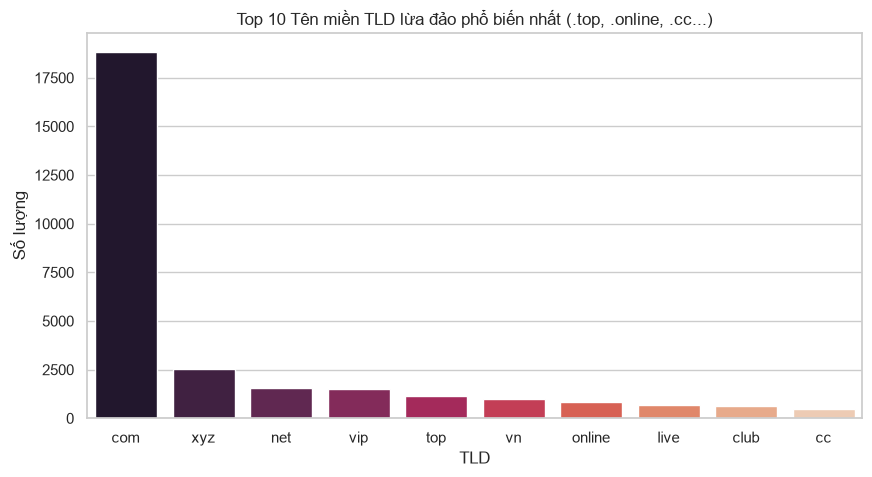

In [5]:
if not combined_df.empty and "tld" in combined_df.columns:
    tld_counts = phish_only["tld"].value_counts().head(10)
    
    plt.figure(figsize=(10, 5))
    sns.barplot(x=tld_counts.index, y=tld_counts.values, palette="rocket")
    plt.title("Top 10 Tên miền TLD lừa đảo phổ biến nhất (.top, .online, .cc...)")
    plt.xlabel("TLD")
    plt.ylabel("Số lượng")
    plt.show()

## 🌍 5. Thống kê Dữ liệu Lừa đảo Quốc tế (Global Datasets)

In [6]:
global_dir = os.path.join(data_dir, "phising-email-dataset")
global_files = [f for f in os.listdir(global_dir) if f.endswith(".csv")] if os.path.exists(global_dir) else []

print(f"📂 Số file dữ liệu quốc tế tìm thấy: {len(global_files)}")
file_stats = []
for gf in global_files:
    fpath = os.path.join(global_dir, gf)
    size_mb = round(os.path.getsize(fpath) / (1024 * 1024), 2)
    file_stats.append({"File": gf, "Size (MB)": size_mb})

df_global_summary = pd.DataFrame(file_stats)
print(df_global_summary)

📂 Số file dữ liệu quốc tế tìm thấy: 8
                 File  Size (MB)
0         CEAS_08.csv      64.76
1           Enron.csv      43.45
2            Ling.csv       8.91
3         Nazario.csv       7.45
4  Nigerian_Fraud.csv       8.77
5  phishing_email.csv     101.67
6            spam.csv       0.48
7     SpamAssasin.csv      14.19


## 🚀 6. Kết luận & Tích hợp vào SafeGuard AI RAG Agent
Toàn bộ kết quả phân tích trên đây đã được tự động đóng gói và tích hợp trực tiếp vào `DatasetLoader` và `RAGAgent` để tra cứu thời gian thực.